# Домашнее задание: Ad-hoc аналитика 

Выполнила: Джафарова Фарида

In [1]:
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import duckdb
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.titlesize"] = 12
pd.set_option("display.width", 200)

BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#8a8984"


def pct(x, d=1):
    return f"{x:.{d}%}".replace(".", ",")


con = duckdb.connect()


def register_csv(name, filename):
    df = pd.read_csv("data/" + filename)
    # year/month/day как строки с ведущими нулями, как партиции в Trino
    df["year"] = df["year"].astype(str)
    df["month"] = df["month"].map(lambda x: f"{x:02d}")
    df["day"] = df["day"].map(lambda x: f"{x:02d}")
    con.register(name, df)
    print(f"{name:15s} {len(df):>7,} строк")
    return df


impressions = register_csv("impressions", "impressions.csv")
clicks = register_csv("clicks", "clicks.csv")
responses = register_csv("responses", "responses.csv")
product_daily = register_csv("product_daily", "product_daily.csv")


def sql(query):
    return con.execute(query).df()

impressions      80,000 строк
clicks            3,837 строк
responses           421 строк
product_daily       252 строк


In [2]:
def wilson_ci(successes, n, z=1.96):
    if n <= 0:
        return (np.nan, np.nan)
    p = successes / n
    denom = 1 + z**2 / n
    center = (p + z**2 / (2 * n)) / denom
    margin = z * np.sqrt((p * (1 - p) + z**2 / (4 * n)) / n) / denom
    return (max(0.0, center - margin), min(1.0, center + margin))


def add_wilson(df, succ, n, prefix):
    df[prefix] = df[succ] / df[n]
    ci = [wilson_ci(s, m) for s, m in zip(df[succ], df[n])]
    df[prefix + "_low"] = [c[0] for c in ci]
    df[prefix + "_high"] = [c[1] for c in ci]
    return df


def summarize_dq(df, key_cols=None):
    rows = [{"проверка": "строк всего", "значение": len(df)},
            {"проверка": "полных дублей строк", "значение": int(df.duplicated().sum())}]
    for c in df.columns:
        rows.append({"проверка": f"пропуски: {c}", "значение": int(df[c].isna().sum())})
    if key_cols:
        rows.append({"проверка": f"дубли по ключу: {'+'.join(key_cols)}",
                     "значение": int(df.duplicated(list(key_cols)).sum())})
    return pd.DataFrame(rows)


def poisson_cdf(k, lam):
    # P(X <= k)
    return sum(math.exp(-lam) * lam**i / math.factorial(i) for i in range(int(k) + 1))


def poisson_sf(k, lam):
    # P(X >= k)
    return 1 - poisson_cdf(k - 1, lam)


## 1. ТЗ до SQL

| Поле ТЗ | Значение |
|---|---|
| Заказчик | Продакт рекламного блока top_search |
| Проблема | 20 июля на Android кликабельность top_search резко выше обычной |
| Цель | Понять, ошибка трекинга это или реальное изменение поведения соискателей |
| Гипотеза | H1, ошибка трекинга: дубли кликов, клики без показа, недописанные показы, клики без откликов. H2, реальный эффект: клики от разных соискателей, отклики растут вместе с кликами |
| Метрика | Кликабельность = клики / показы (не больше одного клика на показ); конверсия из клика в отклик; интервал Уилсона 95% |
| Период | 1–28 июля 2026: 20 июля против остальных 27 дней (фон); отдельно до и после запуска top_boost 15 июля |
| Сегменты | Платформа (iOS и веб как контроль в тот же день); продукт top_search и top_boost; сегмент работодателя |
| Критерий успеха | 1) День аномальный, если интервал кликабельности 20 июля не пересекается с интервалом фона. 2) Ошибка трекинга, если есть хотя бы одно: дубли кликов, клики без показа или с чужими атрибутами, провал числа показов, клики сосредоточены на нескольких соискателях или вакансиях, число откликов ближе к ожиданию «клики фиктивные», чем к ожиданию «клики настоящие». 3) Иначе реальный эффект; смену формата стоит обсуждать, только если рост держится дольше одного дня и есть у top_search, но не у top_boost |
| Решение по результату | Починить логирование / формат не менять и искать внешнюю причину / готовить A/B-тест формата на Android |
| Дедлайн | Завтра к планёрке |
| Глубина | Разбор (ниже) |

**Глубина: разбор.** Цена ошибки средняя: ложная «ошибка трекинга» займёт разработчиков на спринт, ложный «реальный эффект» приведёт к смене формата на Android по артефакту, и несколько недель блок будет работать хуже для части пользователей. Оба действия откатываются без следа (логирование и формат меняются конфигурацией), деньги клиентов напрямую не затронуты, поэтому глубокий разбор не нужен. Прикидки мало: нужны проверка качества данных, контроль по платформам и интервалы.

## 2. Качество данных

Порядок из лекции: размер и дубли, ключи, пропуски, категории, диапазоны. Затем проверки, специфичные для трекинга кликов.

In [3]:
display(summarize_dq(impressions, ["impression_id"]))
display(summarize_dq(clicks, ["click_id"]))
display(summarize_dq(responses, ["response_id"]))

,проверка,значение
0,строк всего,80000
1,полных дублей строк,0
2,пропуски: impression_id,0
3,пропуски: event_date,0
4,пропуски: platform,0
5,пропуски: segment,0
6,пропуски: product,0
7,пропуски: vacancy_id,0
8,пропуски: employer_id,0
9,пропуски: hhuid,0


,проверка,значение
0,строк всего,3837
1,полных дублей строк,0
2,пропуски: click_id,0
3,пропуски: impression_id,0
4,пропуски: event_date,0
5,пропуски: platform,0
6,пропуски: segment,0
7,пропуски: product,0
8,пропуски: vacancy_id,0
9,пропуски: employer_id,0


,проверка,значение
0,строк всего,421
1,полных дублей строк,0
2,пропуски: response_id,0
3,пропуски: click_id,0
4,пропуски: impression_id,0
5,пропуски: event_date,0
6,пропуски: platform,0
7,пропуски: segment,0
8,пропуски: product,0
9,пропуски: vacancy_id,0


In [4]:
# Целостность воронки: каждый клик - ровно на один показ, каждый отклик - на один клик
dq_funnel = sql("""
SELECT 'клики: дубли click_id' AS check_name, COUNT(*) - COUNT(DISTINCT click_id) AS value FROM clicks
UNION ALL
SELECT 'клики: повторные клики на один показ', COUNT(*) - COUNT(DISTINCT impression_id) FROM clicks
UNION ALL
SELECT 'клики без показа', COUNT(*)
FROM clicks c LEFT JOIN impressions i ON i.impression_id = c.impression_id
WHERE i.impression_id IS NULL
UNION ALL
SELECT 'клики: атрибуты не совпадают с показом', COUNT(*)
FROM clicks c JOIN impressions i ON i.impression_id = c.impression_id
WHERE c.event_date <> i.event_date OR c.platform <> i.platform OR c.product <> i.product
   OR c.vacancy_id <> i.vacancy_id OR c.hhuid <> i.hhuid
UNION ALL
SELECT 'клики: соискатель повторно кликнул ту же вакансию',
       COUNT(*) - COUNT(DISTINCT CAST(hhuid AS VARCHAR) || '-' || CAST(vacancy_id AS VARCHAR)) FROM clicks
UNION ALL
SELECT 'отклики: повторные на один клик', COUNT(*) - COUNT(DISTINCT click_id) FROM responses
UNION ALL
SELECT 'отклики без клика', COUNT(*)
FROM responses r LEFT JOIN clicks c ON c.click_id = r.click_id
WHERE c.click_id IS NULL
UNION ALL
SELECT 'отклики: атрибуты не совпадают с кликом', COUNT(*)
FROM responses r JOIN clicks c ON c.click_id = r.click_id
WHERE r.impression_id <> c.impression_id OR r.event_date <> c.event_date
   OR r.platform <> c.platform OR r.product <> c.product
UNION ALL
SELECT 'партиция year/month/day не совпадает с event_date', COUNT(*)
FROM (
    SELECT year, month, day, event_date FROM impressions
    UNION ALL SELECT year, month, day, event_date FROM clicks
    UNION ALL SELECT year, month, day, event_date FROM responses
) t
WHERE year || '-' || month || '-' || day <> event_date
""")
dq_funnel

,check_name,value
0,клики: дубли click_id,0
1,клики: повторные клики на один показ,0
2,клики без показа,0
3,клики: атрибуты не совпадают с показом,0
4,клики: соискатель повторно кликнул ту же вакансию,0
5,отклики: повторные на один клик,0
6,отклики без клика,0
7,отклики: атрибуты не совпадают с кликом,0
8,партиция year/month/day не совпадает с event_date,0


In [5]:
# Категории и диапазоны: нет ли разнобоя в написании платформ и продуктов,
# пишутся ли события на всех платформах каждый день
sql("""
SELECT 'impressions' AS tbl, platform, product, COUNT(*) AS n,
       MIN(event_date) AS first_day, MAX(event_date) AS last_day, COUNT(DISTINCT event_date) AS days
FROM impressions GROUP BY 1, 2, 3
UNION ALL
SELECT 'clicks', platform, product, COUNT(*), MIN(event_date), MAX(event_date), COUNT(DISTINCT event_date)
FROM clicks GROUP BY 1, 2, 3
UNION ALL
SELECT 'responses', platform, product, COUNT(*), MIN(event_date), MAX(event_date), COUNT(DISTINCT event_date)
FROM responses GROUP BY 1, 2, 3
ORDER BY 1, 2, 3
""")

,tbl,platform,product,n,first_day,last_day,days
0,clicks,ANDROID,top_boost,165,2026-07-15,2026-07-28,14
1,clicks,ANDROID,top_search,480,2026-07-01,2026-07-28,28
2,clicks,DESKTOP_WEB,top_boost,424,2026-07-15,2026-07-28,14
3,clicks,DESKTOP_WEB,top_search,1343,2026-07-01,2026-07-28,28
4,clicks,IOS,top_boost,117,2026-07-15,2026-07-28,14
5,clicks,IOS,top_search,377,2026-07-01,2026-07-28,28
6,clicks,MOBILE_WEB,top_boost,219,2026-07-15,2026-07-28,14
7,clicks,MOBILE_WEB,top_search,712,2026-07-01,2026-07-28,28
8,impressions,ANDROID,top_boost,3325,2026-07-15,2026-07-28,14
9,impressions,ANDROID,top_search,14281,2026-07-01,2026-07-28,28


### Проверки трекинга для 20 июля (Android, top_search)

Если показы 20 июля недописаны, кликабельность вырастет за счёт знаменателя. Если клики пишет бот или сбойный клиент, они сосредоточатся на немногих соискателях или вакансиях. Сравниваю с днями после 15 июля: после запуска top_boost показов top_search на Android стало меньше.

In [6]:
concentration = sql("""
WITH d AS (
    SELECT
        i.event_date,
        COUNT(*) AS impressions,
        COUNT(c.click_id) AS clicks,
        COUNT(DISTINCT c.hhuid) AS click_users,
        COUNT(DISTINCT c.vacancy_id) AS click_vacancies,
        COUNT(DISTINCT c.employer_id) AS click_employers
    FROM impressions i
    LEFT JOIN clicks c ON c.impression_id = i.impression_id
    WHERE i.platform = 'ANDROID' AND i.product = 'top_search'
      AND i.year = '2026' AND i.month = '07' AND i.day BETWEEN '01' AND '28'
    GROUP BY 1
)
SELECT
    CASE WHEN event_date = '2026-07-20' THEN '3) 20 июля'
         WHEN event_date >= '2026-07-15' THEN '2) другие дни после 15 июля'
         ELSE '1) дни до 15 июля' END AS days,
    COUNT(*) AS n_days,
    AVG(impressions) AS avg_impressions,
    AVG(clicks) AS avg_clicks,
    AVG(click_users) AS avg_click_users,
    AVG(click_vacancies) AS avg_click_vacancies,
    AVG(click_employers) AS avg_click_employers
FROM d
GROUP BY 1
ORDER BY 1
""")
concentration.round(1)

,days,n_days,avg_impressions,avg_clicks,avg_click_users,avg_click_vacancies,avg_click_employers
0,1) дни до 15 июля,14,636.3,21.2,21.2,21.2,21.2
1,2) другие дни после 15 июля,13,383.8,11.3,11.3,11.3,11.3
2,3) 20 июля,1,383.0,36.0,36.0,36.0,36.0


In [7]:
# Состав кликов 20 июля по сегментам работодателя против состава показов
seg20 = sql("""
SELECT i.segment, COUNT(*) AS impressions, COUNT(c.click_id) AS clicks
FROM impressions i
LEFT JOIN clicks c ON c.impression_id = i.impression_id
WHERE i.platform = 'ANDROID' AND i.product = 'top_search' AND i.event_date = '2026-07-20'
GROUP BY 1
ORDER BY 2 DESC
""")
seg20["impressions_share"] = seg20["impressions"] / seg20["impressions"].sum()
seg20["clicks_share"] = seg20["clicks"] / seg20["clicks"].sum()
seg20 = add_wilson(seg20, "clicks", "impressions", "ctr")
seg20.round(3)

,segment,impressions,clicks,impressions_share,clicks_share,ctr,ctr_low,ctr_high
0,SMB,210,20,0.548,0.556,0.095,0.062,0.143
1,Large,111,12,0.290,0.333,0.108,0.063,0.180
2,Premium,62,4,0.162,0.111,0.065,0.025,0.154


| Что проверила | Что нашла |
|---|---|
| Полные дубли, дубли по ключу, пропуски | Нет ни в одной из трёх таблиц |
| Повторные клики на один показ, клики без показа, расхождение атрибутов клика и показа | Нет: каждый клик привязан ровно к одному показу с той же датой, платформой, продуктом, вакансией и соискателем |
| Отклики без клика, повторные отклики, расхождение атрибутов | Нет |
| Партиции против `event_date`, написание категорий, покрытие дней | Совпадают; четыре платформы и два продукта без разнобоя; события есть на каждой платформе все 28 дней |
| Показы 20 июля (знаменатель) | 383 при обычных ~385 в день после 15 июля: показы не потеряны |
| Концентрация кликов 20 июля | 36 кликов от 36 разных соискателей по 36 разным вакансиям и 36 работодателям |
| Состав по сегментам | Доли сегментов в кликах близки к долям в показах, рост не сосредоточен в одном сегменте работодателей |

Дефектов, которые объясняли бы всплеск, нет. В кейсе 3 на лекции выброс предварительно назвали двойным логированием, но двойное логирование оставило бы повторные клики на один показ или дубли по ключу, а их нет. Остаётся проверить, настоящие ли это клики по воронке.

## 3. Кликабельность по дням с интервалом

In [8]:
daily = sql("""
WITH imp AS (
    SELECT event_date, platform, product, COUNT(*) AS impressions
    FROM impressions
    WHERE year = '2026' AND month = '07' AND day BETWEEN '01' AND '28'
    GROUP BY 1, 2, 3
),
clk AS (
    SELECT event_date, platform, product, COUNT(DISTINCT impression_id) AS clicks
    FROM clicks
    WHERE year = '2026' AND month = '07' AND day BETWEEN '01' AND '28'
    GROUP BY 1, 2, 3
),
rsp AS (
    SELECT event_date, platform, product, COUNT(DISTINCT click_id) AS responses
    FROM responses
    WHERE year = '2026' AND month = '07' AND day BETWEEN '01' AND '28'
    GROUP BY 1, 2, 3
)
SELECT
    i.event_date, i.platform, i.product, i.impressions,
    COALESCE(c.clicks, 0) AS clicks,
    COALESCE(r.responses, 0) AS responses
FROM imp i
LEFT JOIN clk c ON c.event_date = i.event_date AND c.platform = i.platform AND c.product = i.product
LEFT JOIN rsp r ON r.event_date = i.event_date AND r.platform = i.platform AND r.product = i.product
ORDER BY 1, 2, 3
""")
daily["event_date"] = pd.to_datetime(daily["event_date"])
daily = add_wilson(daily, "clicks", "impressions", "ctr")
daily["is_jul20"] = daily["event_date"] == pd.Timestamp("2026-07-20")

# Фон: все дни, кроме 20 июля
fon = (daily[~daily["is_jul20"]]
       .groupby(["platform", "product"], as_index=False)[["impressions", "clicks", "responses"]].sum())
fon = add_wilson(fon, "clicks", "impressions", "ctr")

jul20 = daily[daily["is_jul20"]][["platform", "product", "impressions", "clicks", "ctr", "ctr_low", "ctr_high"]]
cmp20 = jul20.merge(fon[["platform", "product", "ctr", "ctr_low", "ctr_high"]],
                    on=["platform", "product"], suffixes=("_jul20", "_fon"))
cmp20["ratio"] = cmp20["ctr_jul20"] / cmp20["ctr_fon"]
cmp20["anomaly"] = cmp20["ctr_low_jul20"] > cmp20["ctr_high_fon"]  # критерий 1 из ТЗ
cmp20.round(4)

,platform,product,impressions,clicks,ctr_jul20,ctr_low_jul20,ctr_high_jul20,ctr_fon,ctr_low_fon,ctr_high_fon,ratio,anomaly
0,ANDROID,top_boost,252,29,0.1151,0.0813,0.1604,0.0443,0.0375,0.0521,2.6003,True
1,ANDROID,top_search,383,36,0.0940,0.0687,0.1274,0.0319,0.0292,0.0350,2.9422,True
2,DESKTOP_WEB,top_boost,429,34,0.0793,0.0573,0.1087,0.0719,0.0653,0.0791,1.1024,False
3,DESKTOP_WEB,top_search,714,47,0.0658,0.0499,0.0864,0.0549,0.0520,0.0579,1.1994,False
4,IOS,top_boost,186,8,0.0430,0.0220,0.0826,0.0423,0.0352,0.0507,1.0177,False
5,IOS,top_search,293,9,0.0307,0.0162,0.0573,0.0318,0.0288,0.0352,0.9652,False
6,MOBILE_WEB,top_boost,246,14,0.0569,0.0342,0.0932,0.0659,0.0577,0.0752,0.8631,False
7,MOBILE_WEB,top_search,406,32,0.0788,0.0564,0.1092,0.0492,0.0457,0.0529,1.6030,True


In [9]:
# Конверсия из клика в отклик: настоящие ли клики 20 июля.
# Всплеск есть в обоих форматах Android, поэтому проверяю Android целиком и отдельно top_search.
LAUNCH = pd.Timestamp("2026-07-15")
android = daily[daily["platform"] == "ANDROID"]

rows = []
for label, part in [("Android, оба формата", android),
                    ("Android, top_search", android[android["product"] == "top_search"])]:
    d20 = part[part["is_jul20"]][["impressions", "clicks", "responses"]].sum()
    base = part[~part["is_jul20"]][["impressions", "clicks", "responses"]].sum()
    exp_fake = d20["impressions"] * base["responses"] / base["impressions"]  # лишние клики без откликов
    exp_real = d20["clicks"] * base["responses"] / base["clicks"]            # все клики с обычной конверсией
    rows.append({
        "срез": label,
        "клики 20.07": int(d20["clicks"]),
        "отклики 20.07": int(d20["responses"]),
        "ожидание, если клики фиктивные": exp_fake,
        "ожидание, если клики настоящие": exp_real,
        "P(не меньше факта | фиктивные)": poisson_sf(d20["responses"], exp_fake),
        "P(не больше факта | настоящие)": poisson_cdf(d20["responses"], exp_real),
        "конверсия 20.07": d20["responses"] / d20["clicks"],
        "конверсия фон": base["responses"] / base["clicks"],
    })
resp_test = pd.DataFrame(rows)
resp_test.round(3)

,срез,клики 20.07,отклики 20.07,"ожидание, если клики фиктивные","ожидание, если клики настоящие",P(не меньше факта | фиктивные),P(не больше факта | настоящие),конверсия 20.07,конверсия фон
0,"Android, оба формата",65,8,3.405,10.198,0.023,0.311,0.123,0.157
1,"Android, top_search",36,4,1.736,5.108,0.099,0.422,0.111,0.142


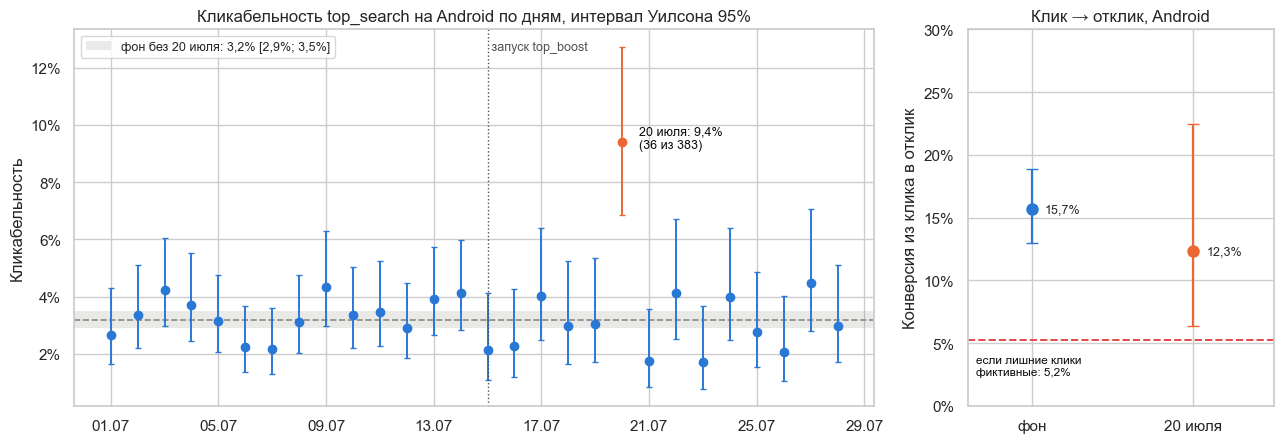

In [10]:
# График 1: дневная кликабельность top_search на Android с интервалом + конверсия из клика в отклик
ts = android[android["product"] == "top_search"].sort_values("event_date")
f_ts = fon[(fon["platform"] == "ANDROID") & (fon["product"] == "top_search")].iloc[0]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [3, 1.15]})

ax1.axhspan(f_ts["ctr_low"], f_ts["ctr_high"], color=GREY, alpha=0.18, lw=0,
            label=f"фон без 20 июля: {pct(f_ts['ctr'])} [{pct(f_ts['ctr_low'])}; {pct(f_ts['ctr_high'])}]")
ax1.axhline(f_ts["ctr"], color=GREY, lw=1.2, ls="--")
for is20, color in [(False, BLUE), (True, ORANGE)]:
    p = ts[ts["is_jul20"] == is20]
    ax1.errorbar(p["event_date"], p["ctr"],
                 yerr=[p["ctr"] - p["ctr_low"], p["ctr_high"] - p["ctr"]],
                 fmt="o", ms=6, color=color, ecolor=color, elinewidth=1.4, capsize=2)
r20 = ts[ts["is_jul20"]].iloc[0]
ax1.annotate(f"20 июля: {pct(r20['ctr'])}\n({int(r20['clicks'])} из {int(r20['impressions'])})",
             (r20["event_date"], r20["ctr"]), xytext=(12, -4), textcoords="offset points",
             fontsize=9, color="#0b0b0b")
ax1.axvline(LAUNCH, color="#52514e", lw=1, ls=":")
ax1.text(LAUNCH, ax1.get_ylim()[1] * 0.97, " запуск top_boost", fontsize=9, color="#52514e", va="top")
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax1.legend(loc="upper left", fontsize=9)
ax1.set_title("Кликабельность top_search на Android по дням, интервал Уилсона 95%")
ax1.set_ylabel("Кликабельность")
ax1.set_xlabel("")
ax1.tick_params(axis="x", rotation=0)
import matplotlib.dates as mdates
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%d.%m"))

# Правая панель: конверсия из клика в отклик, Android, оба формата
a20 = android[android["is_jul20"]][["clicks", "responses", "impressions"]].sum()
ab = android[~android["is_jul20"]][["clicks", "responses", "impressions"]].sum()
conv = pd.DataFrame({"label": ["фон", "20 июля"],
                     "responses": [ab["responses"], a20["responses"]],
                     "clicks": [ab["clicks"], a20["clicks"]]})
conv = add_wilson(conv, "responses", "clicks", "cvr")
for i, (r, color) in enumerate(zip(conv.itertuples(), [BLUE, ORANGE])):
    ax2.errorbar(i, r.cvr, yerr=[[r.cvr - r.cvr_low], [r.cvr_high - r.cvr]],
                 fmt="o", ms=8, color=color, elinewidth=1.6, capsize=4)
    ax2.text(i + 0.08, r.cvr, pct(r.cvr), va="center", fontsize=9)
fake_cvr = (a20["impressions"] * ab["responses"] / ab["impressions"]) / a20["clicks"]
ax2.axhline(fake_cvr, color="#e34948", lw=1.4, ls="--")
ax2.text(-0.35, fake_cvr - 0.012, f"если лишние клики\nфиктивные: {pct(fake_cvr)}",
         fontsize=8.5, color="#0b0b0b", va="top")
ax2.set_xticks([0, 1], conv["label"])
ax2.set_xlim(-0.4, 1.5)
ax2.set_ylim(0, 0.3)
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax2.set_title("Клик → отклик, Android")
ax2.set_ylabel("Конверсия из клика в отклик")

plt.tight_layout()
plt.savefig("graph1_ctr_ci.png", dpi=150, bbox_inches="tight")
plt.show()

Слева: 20 июля кликабельность top_search на Android в 2,9 раза выше фона, интервалы не пересекаются, остальные дни лежат в обычном коридоре. Справа: лишние клики дали отклики. Если бы они были фиктивными, конверсия упала бы примерно до 5%, а она 12% и статистически не отличается от фона.

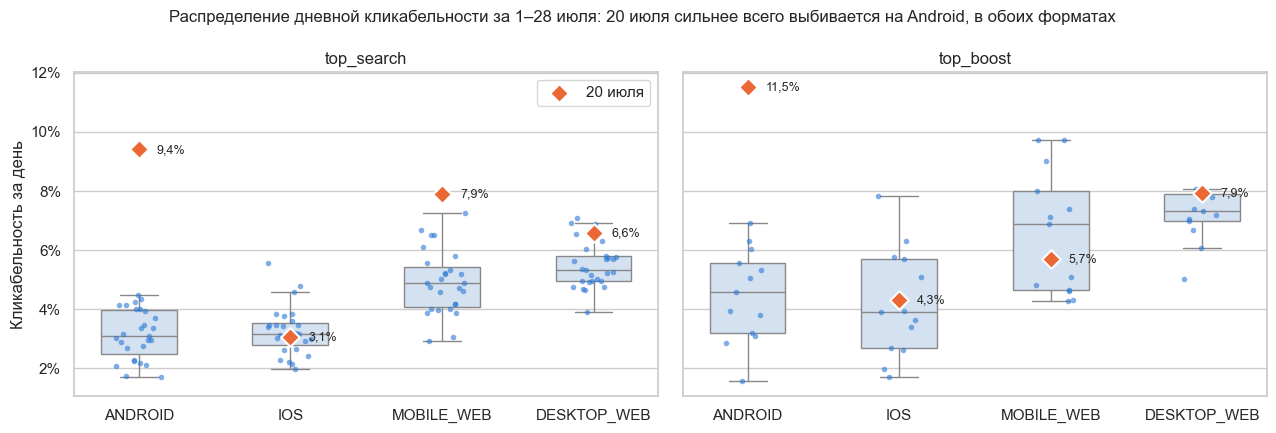

In [11]:
# График 2: распределение дневной кликабельности по платформам и продуктам, 20 июля отмечено
order = ["ANDROID", "IOS", "MOBILE_WEB", "DESKTOP_WEB"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
for ax, prod in zip(axes, ["top_search", "top_boost"]):
    part = daily[daily["product"] == prod]
    sns.boxplot(data=part[~part["is_jul20"]], x="platform", y="ctr", order=order, ax=ax,
                color="#cfe0f5", width=0.5, fliersize=0, linewidth=1)
    sns.stripplot(data=part[~part["is_jul20"]], x="platform", y="ctr", order=order, ax=ax,
                  color=BLUE, size=4, alpha=0.6, jitter=0.15)
    p20 = part[part["is_jul20"]].set_index("platform").reindex(order)
    ax.scatter(range(len(order)), p20["ctr"], color=ORANGE, s=90, marker="D", zorder=5,
               edgecolor="white", linewidth=1.5, label="20 июля")
    for i, v in enumerate(p20["ctr"]):
        ax.text(i + 0.12, v, pct(v), fontsize=9, va="center")
    ax.set_title(prod)
    ax.set_xlabel("")
    ax.set_ylabel("Кликабельность за день" if prod == "top_search" else "")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
axes[0].legend(loc="upper right")
fig.suptitle("Распределение дневной кликабельности за 1–28 июля: 20 июля сильнее всего выбивается на Android, в обоих форматах",
             fontsize=12)
plt.tight_layout()
plt.savefig("graph2_ctr_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

Всплеск не ограничен top_search: на Android top_boost 20 июля тоже вырос примерно в 2,6 раза. На мобильном вебе top_search рост слабее (в 1,6 раза), на iOS и десктопе день обычный. Значит, причина общая для Android в этот день, а не в формате top_search. Мобильный веб работает в браузере, и события там, скорее всего, собираются отдельно от приложения Android, поэтому сбой логирования в приложении вряд ли объяснил бы рост на мобильном вебе.

## 4. Устойчивость эффекта и чувствительность вывода

In [12]:
def pooled(part, label):
    s = part[["impressions", "clicks"]].sum()
    lo, hi = wilson_ci(s["clicks"], s["impressions"])
    return {"срез": label, "показы": int(s["impressions"]), "клики": int(s["clicks"]),
            "кликабельность": s["clicks"] / s["impressions"], "ci_low": lo, "ci_high": hi}

d = ts["event_date"]
stab = pd.DataFrame([
    pooled(ts[d < LAUNCH], "1–14 июля (до запуска top_boost)"),
    pooled(ts[(d >= LAUNCH) & (d < "2026-07-20")], "15–19 июля"),
    pooled(ts[ts["is_jul20"]], "20 июля"),
    pooled(ts[d > "2026-07-20"], "21–28 июля"),
    pooled(ts, "весь июль с 20 июля"),
    pooled(ts[~ts["is_jul20"]], "весь июль без 20 июля"),
])
display(stab.round(4))

# Для сравнения: июльская кликабельность top_search на других платформах
display(fon[fon["product"] == "top_search"][["platform", "ctr", "ctr_low", "ctr_high"]].round(4))

,срез,показы,клики,кликабельность,ci_low,ci_high
0,1–14 июля (до запуска top_boost),8908,297,0.0333,0.0298,0.0373
1,15–19 июля,1905,55,0.0289,0.0222,0.0374
2,20 июля,383,36,0.0940,0.0687,0.1274
3,21–28 июля,3085,92,0.0298,0.0244,0.0364
4,весь июль с 20 июля,14281,480,0.0336,0.0308,0.0367
5,весь июль без 20 июля,13898,444,0.0319,0.0292,0.0350


,platform,ctr,ctr_low,ctr_high
1,ANDROID,0.0319,0.0292,0.0350
3,DESKTOP_WEB,0.0549,0.0520,0.0579
5,IOS,0.0318,0.0288,0.0352
7,MOBILE_WEB,0.0492,0.0457,0.0529


- 21 июля кликабельность вернулась к обычному уровню, рост длился один день.
- До и после запуска top_boost кликабельность top_search на Android одинакова в пределах интервалов: запуск top_boost на неё заметно не повлиял.
- Исключение 20 июля меняет июльскую кликабельность Android с 3,4% до 3,2% и не меняет вывод кейса 3: на Android она ниже, чем на вебе.
- Лишних кликов 20 июля около 25, а 19 и 21 июля вместе не хватает примерно 5 кликов до обычного уровня, поэтому перенос событий из соседних дней всплеск не объясняет.

### Решение по критериям ТЗ

| Критерий | Результат | Вывод |
|---|---|---|
| 1. День аномальный | Интервал 20 июля [6,9%; 12,7%] против фона [2,9%; 3,5%]; по тому же критерию слабее выбивается мобильный веб top_search | Аномалия есть |
| 2. Дефекты событий | Дублей, кликов без показа, расхождений атрибутов, провала показов, концентрации нет | Признаков ошибки трекинга нет |
| 2. Отклики | 8 откликов на Android при ожидании 3,4 («фиктивные») и 10,2 («настоящие»); вероятность получить 8 и больше при фиктивных кликах около 2% | Клики настоящие |
| 3. Устойчивость | Рост один день, 21 июля уровень обычный | Не устойчиво |
| 3. Связь с форматом | top_boost на Android вырос так же | К формату top_search не относится |

**Рекомендую не чинить логирование и не менять формат показа на Android.** Всплеск похож на реальные клики, но он однодневный и общий для обоих форматов Android, поэтому оснований для смены формата нет. Причину стоит искать вне формата: что было в приложении Android 20 июля (релиз, пуш, рассылка, акция).

## 5. Ограничения

- В событиях нет времени внутри дня, версии приложения и логов клиента: не проверила, сосредоточен ли всплеск в нескольких часах и совпадает ли он с релизом.
- Ошибку атрибуции (органические клики Android записались как рекламные вместе со своими откликами) по этим данным не отличить от реального эффекта: она поднимает клики и отклики одинаково. Исключить её можно только сверкой с общим числом кликов в приложении.
- Откликов мало: по одному top_search проверка слабая (4 отклика и больше при фиктивных кликах получаются с вероятностью около 10%), уверенный вывод получается только по двум форматам Android вместе.
- 168 ячеек «день × платформа × продукт»: отдельные выбросы, как у мобильного веба 20 июля, могут быть случайными.
- После 15 июля показов top_search на Android примерно на 40% меньше, поэтому дневная кликабельность шумнее и интервалы шире.
- Данных о маркетинговых активностях 20 июля нет; данные синтетические.

## 6. Бонус: связь с расходом top_search и top_boost после 15 июля

,в среднем за день до 15.07,в среднем за день после 15.07 (без 20.07),20 июля,"20 июля, z-оценка к дням после 15.07",изменение после запуска
product,,,,,
top_search,688587.99,573126.07,572074.22,-0.09,-0.17
top_boost,0.00,204462.88,207690.42,0.80,NaN
total,688587.99,777588.96,779764.64,0.15,0.13


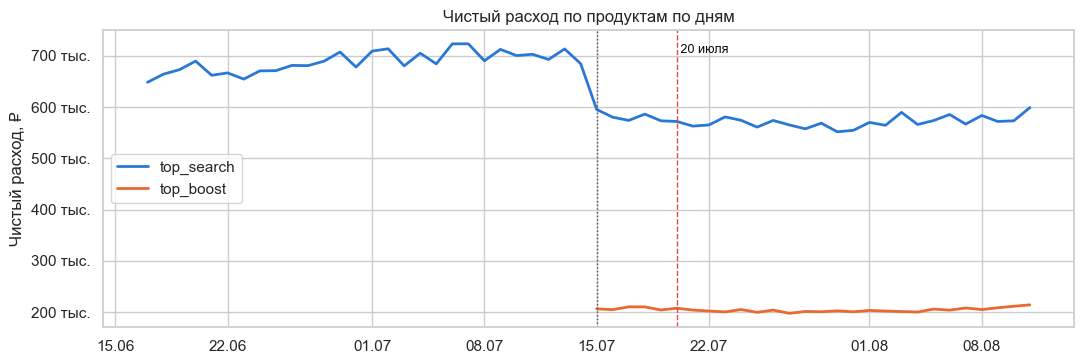

In [13]:
pdly = product_daily.copy()
pdly["event_date"] = pd.to_datetime(pdly["event_date"])
spend = pdly.groupby(["event_date", "product"])["net_spend"].sum().unstack().fillna(0)
spend["total"] = spend.sum(axis=1)

pre = spend[spend.index < LAUNCH].mean()
post = spend[(spend.index >= LAUNCH) & (spend.index != "2026-07-20")]
s20 = spend.loc["2026-07-20"]
bonus = pd.DataFrame({
    "в среднем за день до 15.07": pre,
    "в среднем за день после 15.07 (без 20.07)": post.mean(),
    "20 июля": s20,
    "20 июля, z-оценка к дням после 15.07": (s20 - post.mean()) / post.std(),
}).loc[["top_search", "top_boost", "total"]]
bonus["изменение после запуска"] = (bonus["в среднем за день после 15.07 (без 20.07)"]
                                   / bonus["в среднем за день до 15.07"].replace(0, np.nan) - 1)
display(bonus.round(2))

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(spend.index, spend["top_search"], color=BLUE, lw=2, label="top_search")
ax.plot(spend.index, spend["top_boost"].replace(0, np.nan), color=ORANGE, lw=2, label="top_boost")
ax.axvline(LAUNCH, color="#52514e", lw=1, ls=":")
ax.axvline(pd.Timestamp("2026-07-20"), color="#e34948", lw=1, ls="--")
ax.text(pd.Timestamp("2026-07-20"), spend["top_search"].max(), " 20 июля", color="#0b0b0b", fontsize=9, va="top")
ax.set_title("Чистый расход по продуктам по дням")
ax.set_ylabel("Чистый расход, ₽")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1000:.0f} тыс."))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d.%m"))
ax.legend(loc="center left")
plt.tight_layout()
plt.show()

После 15 июля расход top_search просел ступенькой, а top_boost добрал больше, и суммарный расход вырос. Эта перестройка началась 15 июля и идёт ровно, 20 июля в расходе не видно ни по одному продукту. Значит, на списаниях клиентов всплеск кликов не отразился. После запуска на Android изменился объём показов top_search (примерно на 40% меньше), а не его кликабельность, поэтому вопрос о смене формата на Android стоит решать по данным за весь период после запуска, а не по одному дню. Витрина `product_daily` не разбита по платформам и по масштабу не сверяется с событийными таблицами, поэтому вторым источником для кликов Android она служить не может.

## 7. Итоговая справка

**Решение.** Рекомендую не чинить логирование и не менять формат показа top_search на Android. Всплеск 20 июля похож на настоящие клики, но длился один день и затронул оба рекламных формата Android, поэтому к формату top_search он не относится.

**Контекст.** 20 июля кликабельность top_search на Android резко выше обычной. Если это ошибка трекинга, нужно чинить логирование; если реальный эффект, решать, менять ли формат. Глубина: разбор (цена ошибки средняя, оба решения откатываются без следа).

**Что сделала.** Проверила качество показов, кликов и откликов; сравнила 20 июля с остальными днями 1–28 июля по платформам и продуктам с интервалом Уилсона 95%; проверила, дали ли лишние клики отклики; посмотрела устойчивость эффекта и расход.

**Результат.**
- Аномалия реальная: кликабельность 9,4% [6,9%; 12,7%] против 3,2% [2,9%; 3,5%] в остальные дни, в 2,9 раза выше.
- Следов ошибки трекинга нет: ни дублей, ни кликов без показа, показов 383 при обычных 384, 36 кликов от 36 разных соискателей.
- Клики настоящие: на Android 8 откликов при ожидании 3,4, если бы лишние клики были фиктивными, и 10,2, если они настоящие. При фиктивных кликах 8 откликов и больше получаются с вероятностью около 2%.
- Причина не в формате: top_boost на Android в тот же день вырос в 2,6 раза, мобильный веб слабее, iOS и десктоп в норме. 21 июля уровень уже обычный.
- В расходе top_search и top_boost 20 июля не виден, на списаниях клиентов всплеск не отразился.

![Кликабельность top_search на Android по дням с интервалом Уилсона 95% и конверсия из клика в отклик](graph1_ctr_ci.png)

![Распределение дневной кликабельности за 1–28 июля по платформам и продуктам](graph2_ctr_distribution.png)

**Ограничения.** Нет времени события, версии приложения и логов клиента. Ошибку атрибуции (органические клики записались как рекламные вместе с откликами) по этим данным не отличить от реального эффекта. Откликов мало, уверенный вывод получается только по двум форматам Android вместе.

**Что можно сделать дальше.** Запросить у команды приложения Android и CRM, что было 20 июля (релиз, пуш, рассылка). Сверить общее число кликов в приложении за 20 июля: если всплеск есть и там, ошибку атрибуции можно исключить. Вопрос о смене формата на Android решать по данным за весь период после запуска top_boost, а не по одному дню.